# HW2. Классификация снимков МРТ

Крутько А. С., 640-01

Сравнение своей CNN и предобученной ResNet18 на [датасете из задания](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset). У них будут одинаковые обучающие и тестовые изображения.

## Данные

загрузка датасета (+сколько в нём снимков каждого класса. В `Training` находятся изображения для обучения, в `Testing` для итоговой проверки.)

In [1]:
%pip -q install kagglehub

In [2]:
import copy
import random
import time
from collections import Counter
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

Устройство: cuda


In [3]:
path = Path(kagglehub.dataset_download('masoudnickparvar/brain-tumor-mri-dataset'))
train_folder = path / 'Training'
test_folder = path / 'Testing'

train_data = datasets.ImageFolder(train_folder)
test_data = datasets.ImageFolder(test_folder)
class_names = train_data.classes

print('Классы:', class_names)
print('Обучающих снимков:', len(train_data))
print('Тестовых снимков:', len(test_data))
counts = Counter(train_data.targets)
print('Снимков по классам:', {name: counts[i] for i, name in enumerate(class_names)})

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
Обучающих снимков: 5600
Тестовых снимков: 1600
Снимков по классам: {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}


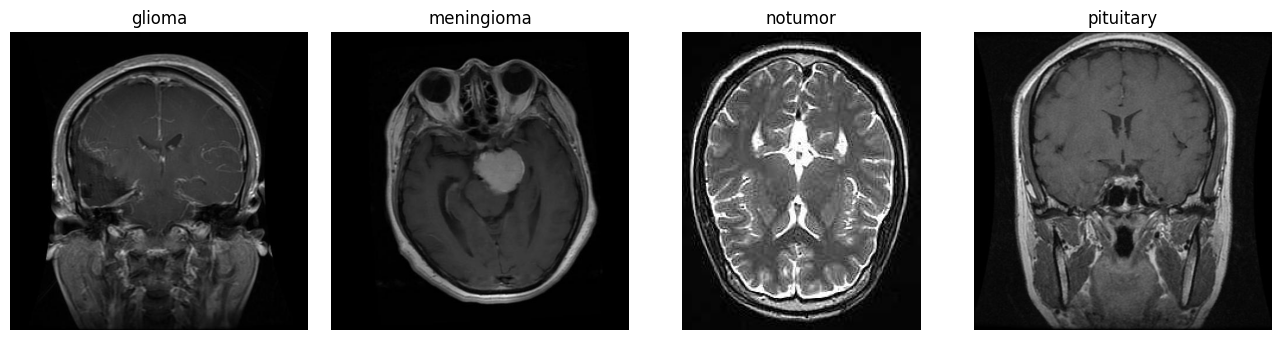

In [4]:
fig, axes = plt.subplots(1, len(class_names), figsize=(13, 3.5))
for ax, class_name in zip(axes, class_names):
    image_path = next(path for path, label in train_data.samples
                      if label == train_data.class_to_idx[class_name])
    with Image.open(image_path) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(class_name)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Подготовка изображений

Из `Training` оставляю 20% снимков для проверки во время обучения, это будет validation. Тестовые снимки пока не трогаю.

Все изображения приведу к размеру 160 × 160. `ImageFolder` преобразует их в RGB, то есть в три канала, как ожидает ResNet18. При обучении слегка поворачиваю снимки, чтобы сеть не привыкала к одному положению. Нормализацию беру такую же, как для предобученной ResNet18; обе модели получат одинаковые входные данные.

In [5]:
indices = np.arange(len(train_data))
train_indices, val_indices = train_test_split(
    indices, test_size=0.2, random_state=42, stratify=train_data.targets
)
print('Train:', len(train_indices), 'Validation:', len(val_indices), 'Test:', len(test_data))

image_size = 160
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_set = Subset(datasets.ImageFolder(train_folder, transform=train_transform), train_indices)
val_set = Subset(datasets.ImageFolder(train_folder, transform=eval_transform), val_indices)
test_set = datasets.ImageFolder(test_folder, transform=eval_transform)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=32, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, num_workers=2)

Train: 4480 Validation: 1120 Test: 1600


## Обучение моделей

После каждоф эпохи проверяю её на validation без изменения весов. Запомню состояние с лучшей точностью на validation, а не состояние после последней эпохи.

In [6]:
loss_fn = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct = 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0, 0
    true_labels, predictions = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += loss_fn(logits, labels).item() * len(labels)
        predicted = logits.argmax(1)
        correct += (predicted == labels).sum().item()
        true_labels.extend(labels.cpu().tolist())
        predictions.extend(predicted.cpu().tolist())
    return total_loss / len(loader.dataset), correct / len(loader.dataset), true_labels, predictions

def fit(model, optimizer, epochs, name):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_accuracy = -1
    best_weights = copy.deepcopy(model.state_dict())
    start = time.time()
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc, _, _ = evaluate(model, val_loader)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        if val_acc > best_accuracy:
            best_accuracy = val_acc
            best_weights = copy.deepcopy(model.state_dict())
        print(f'{name}, эпоха {epoch + 1}/{epochs}: '
              f'train acc={train_acc:.3f}, val acc={val_acc:.3f}')
    model.load_state_dict(best_weights)
    history['minutes'] = (time.time() - start) / 60
    return history

## Своя CNN

Сеть состоит из четырёх одинаковых блоков. `Conv2d` ищет признаки на снимке, `BatchNorm2d` помогает обучению быть стабильнее, `ReLU` добавляет нелинейность, а `MaxPool2d` уменьшает изображение вдвое. В конце `AdaptiveAvgPool2d` оставляет по одному числу для каждого из 256 признаков; последний слой превращает их в четыре оценки — по одной на класс. Веса этой сети в начале случайные.

In [7]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        layers = []
        channels = [3, 32, 64, 128, 256]
        for in_channels, out_channels in zip(channels[:-1], channels[1:]):
            layers.extend([
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(2),
            ])
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = SimpleCNN(len(class_names)).to(device)
cnn_optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3)
cnn_history = fit(cnn, cnn_optimizer, epochs=12, name='SimpleCNN')

SimpleCNN, эпоха 1/12: train acc=0.708, val acc=0.771
SimpleCNN, эпоха 2/12: train acc=0.780, val acc=0.765
SimpleCNN, эпоха 3/12: train acc=0.799, val acc=0.415
SimpleCNN, эпоха 4/12: train acc=0.814, val acc=0.474
SimpleCNN, эпоха 5/12: train acc=0.825, val acc=0.792
SimpleCNN, эпоха 6/12: train acc=0.846, val acc=0.849
SimpleCNN, эпоха 7/12: train acc=0.852, val acc=0.718
SimpleCNN, эпоха 8/12: train acc=0.845, val acc=0.770
SimpleCNN, эпоха 9/12: train acc=0.856, val acc=0.665
SimpleCNN, эпоха 10/12: train acc=0.869, val acc=0.776
SimpleCNN, эпоха 11/12: train acc=0.871, val acc=0.699
SimpleCNN, эпоха 12/12: train acc=0.875, val acc=0.763


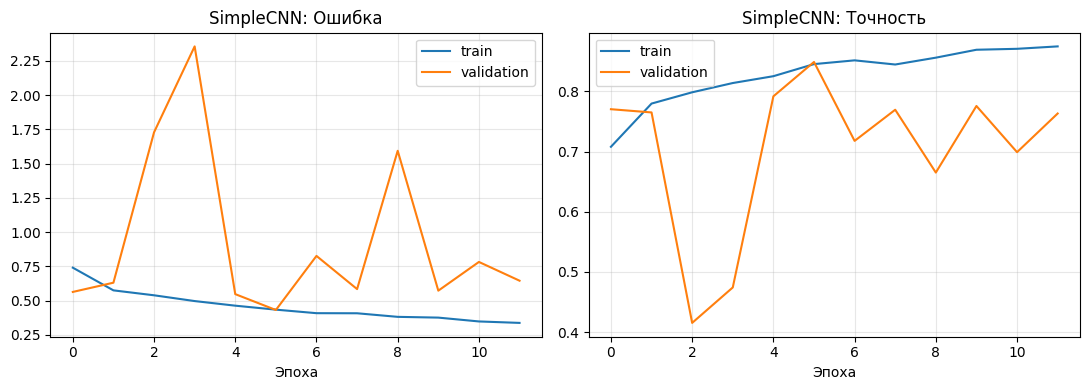

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ('loss', 'acc'), ('Ошибка', 'Точность')):
    ax.plot(cnn_history['train_' + metric], label='train')
    ax.plot(cnn_history['val_' + metric], label='validation')
    ax.set_title('SimpleCNN: ' + title)
    ax.set_xlabel('Эпоха')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
previous_cnn = copy.deepcopy(cnn)
previous_val = max(cnn_history['val_acc'])

smaller_lr_optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-4)
extra_history = fit(cnn, smaller_lr_optimizer, epochs=4, name='SimpleCNN, lr=1e-4')

print('Было на validation:', previous_val)
print('После дополнительных эпох:', max(extra_history['val_acc']))

SimpleCNN, lr=1e-4, эпоха 1/4: train acc=0.872, val acc=0.879
SimpleCNN, lr=1e-4, эпоха 2/4: train acc=0.879, val acc=0.865
SimpleCNN, lr=1e-4, эпоха 3/4: train acc=0.881, val acc=0.884
SimpleCNN, lr=1e-4, эпоха 4/4: train acc=0.882, val acc=0.802
Было на validation: 0.8491071428571428
После дополнительных эпох: 0.8839285714285714


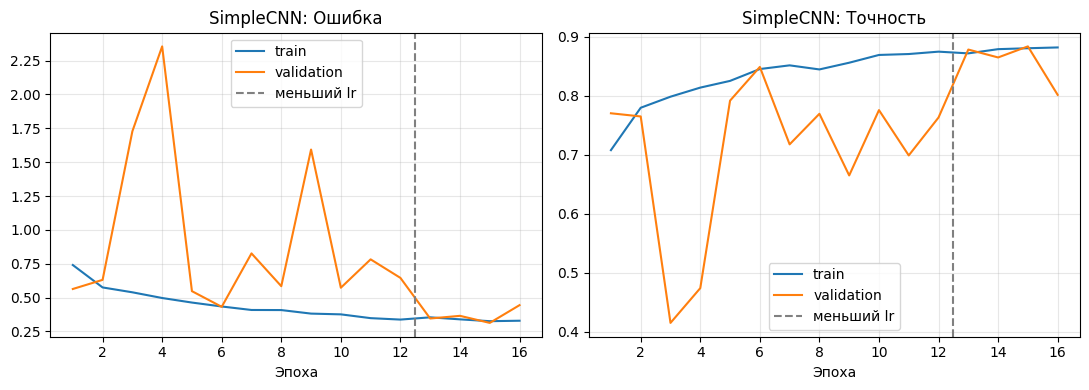

In [10]:
full_cnn_history = {
    key: cnn_history[key] + extra_history[key]
    for key in ('train_loss', 'val_loss', 'train_acc', 'val_acc')
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ('loss', 'acc'), ('Ошибка', 'Точность')):
    epochs = range(1, 17)
    ax.plot(epochs, full_cnn_history['train_' + metric], label='train')
    ax.plot(epochs, full_cnn_history['val_' + metric], label='validation')
    ax.axvline(12.5, color='gray', linestyle='--', label='меньший lr')
    ax.set_title('SimpleCNN: ' + title)
    ax.set_xlabel('Эпоха')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## ResNet18

Здесь беру готовые веса сети, которая раньше училась распознавать изображения ImageNet. Последний слой заменяю: вместо исходных 1000 категорий нужны наши четыре. Затем дообучаю **всю** сеть на МРТ с небольшим шагом обучения.

In [11]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, len(class_names))
resnet = resnet.to(device)

resnet_optimizer = torch.optim.AdamW(resnet.parameters(), lr=1e-4)
resnet_history = fit(resnet, resnet_optimizer, epochs=6, name='ResNet18')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


ResNet18, эпоха 1/6: train acc=0.895, val acc=0.949
ResNet18, эпоха 2/6: train acc=0.969, val acc=0.938
ResNet18, эпоха 3/6: train acc=0.983, val acc=0.967
ResNet18, эпоха 4/6: train acc=0.990, val acc=0.966
ResNet18, эпоха 5/6: train acc=0.988, val acc=0.966
ResNet18, эпоха 6/6: train acc=0.990, val acc=0.977


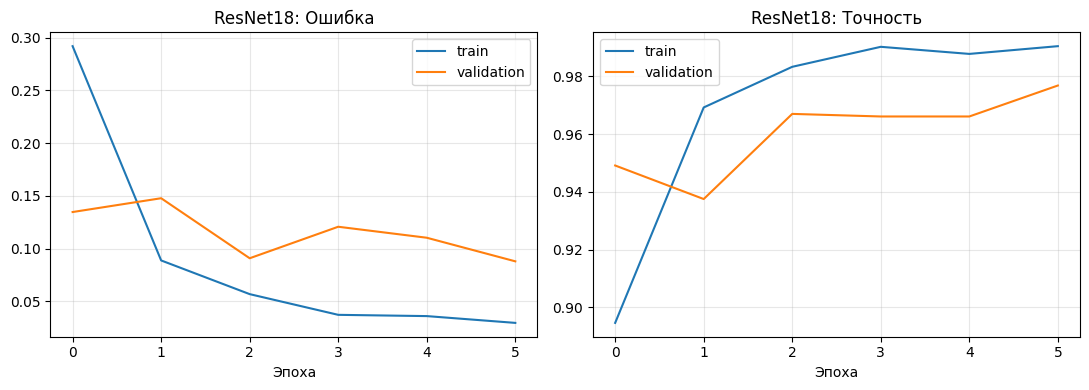

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ('loss', 'acc'), ('Ошибка', 'Точность')):
    ax.plot(resnet_history['train_' + metric], label='train')
    ax.plot(resnet_history['val_' + metric], label='validation')
    ax.set_title('ResNet18: ' + title)
    ax.set_xlabel('Эпоха')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Сравнение на тестовых снимках

сейчас модели выбрала по validation, один раз проверю их на `Testing`. Как просто правильные ответы (`accuracy`), так и `macro-F1`, чтобы учесть качество каждого класса одинаково. + Матрицы ошибок

In [13]:
_, cnn_accuracy, true_labels, cnn_predictions = evaluate(cnn, test_loader)
_, resnet_accuracy, _, resnet_predictions = evaluate(resnet, test_loader)

print('SimpleCNN')
print(classification_report(true_labels, cnn_predictions, target_names=class_names, digits=3))
print('ResNet18')
print(classification_report(true_labels, resnet_predictions, target_names=class_names, digits=3))

cnn_f1 = f1_score(true_labels, cnn_predictions, average='macro')
resnet_f1 = f1_score(true_labels, resnet_predictions, average='macro')
print(f'SimpleCNN: accuracy={cnn_accuracy:.3f}, macro-F1={cnn_f1:.3f}, '
      f'обучение={(cnn_history["minutes"] + extra_history["minutes"]):.1f} мин')
print(f'ResNet18:  accuracy={resnet_accuracy:.3f}, macro-F1={resnet_f1:.3f}, '
      f'обучение={resnet_history["minutes"]:.1f} мин')

SimpleCNN
              precision    recall  f1-score   support

      glioma      0.883     0.662     0.757       400
  meningioma      0.749     0.680     0.713       400
     notumor      0.802     0.985     0.884       400
   pituitary      0.850     0.948     0.896       400

    accuracy                          0.819      1600
   macro avg      0.821     0.819     0.813      1600
weighted avg      0.821     0.819     0.813      1600

ResNet18
              precision    recall  f1-score   support

      glioma      1.000     0.752     0.859       400
  meningioma      0.871     0.978     0.921       400
     notumor      0.920     1.000     0.958       400
   pituitary      0.959     0.995     0.977       400

    accuracy                          0.931      1600
   macro avg      0.937     0.931     0.929      1600
weighted avg      0.937     0.931     0.929      1600

SimpleCNN: accuracy=0.819, macro-F1=0.813, обучение=5.6 мин
ResNet18:  accuracy=0.931, macro-F1=0.929, обучение

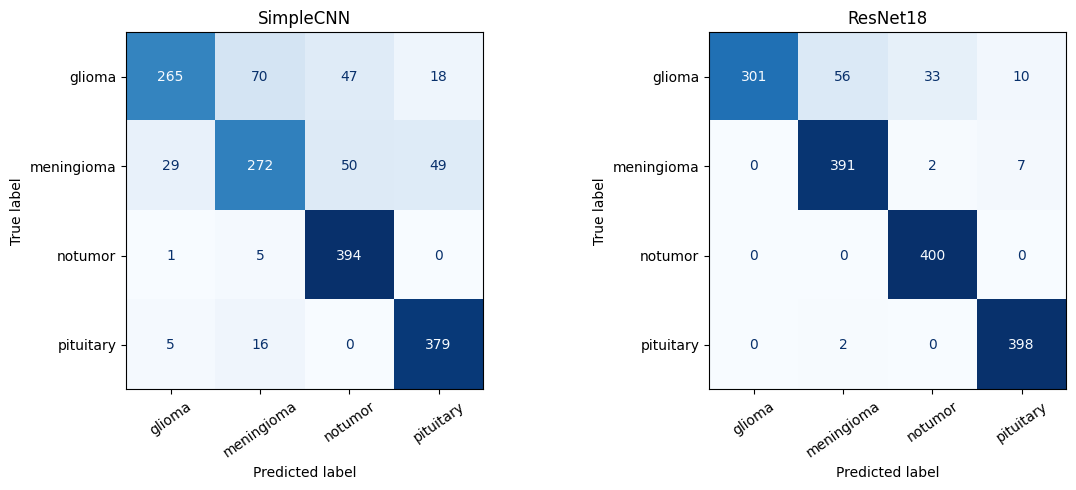

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, predictions in zip(
    axes, ('SimpleCNN', 'ResNet18'), (cnn_predictions, resnet_predictions)
):
    ConfusionMatrixDisplay.from_predictions(
        true_labels, predictions, display_labels=class_names,
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(name)
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

## Выводы

Я обучила две модели на одном датасете из четырёх классов и проверила их на одинаковых 1600 тестовых снимках. После первых 12 эпох у моей CNN точность на validation сильно колебалась. Я уменьшила шаг обучения с 1e-3 до 1e-4 и продолжила обучение ещё четыре эпохи: лучшая точность на validation выросла с 84,9% до 88,4%.

ResNet18 после дообучения получила на тесте 93,1% правильных ответов против 81,9% у моей CNN. По macro-F1 результат также выше: 0,929 против 0,813. Из матриц ошибок видно, что обеим моделям сложнее всего даётся класс glioma.

В этом эксперименте ResNet18 справилась лучше. Она начала с весов, уже обученных на большом наборе изображений, а моя CNN училась с нуля. При этом модели различаются и архитектурой, поэтому по одному этому сравнению нельзя утверждать, что вся разница связана только с предобучением.
